Question 1

In [13]:
# WHOLESALE CUSTOMER SEGMENTATION
# Data exploration, preparation and Hopkins statistic

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

#  Loading the dataset
df = pd.read_csv("wholesale-customers.csv")

print("Dataset shape:", df.shape)
print(df.head())

# Identifying the data types
print("\nDATA TYPES")
print(df.dtypes)

#  Checking for  missing values
print("\nMISSING VALUES")
print(df.isnull().sum())

#  Checking for duplicates
print("\nDUPLICATE RECORDS:", df.duplicated().sum())

# Identify numerical columns (integers and floats)
numerical_cols = df.select_dtypes(include=['number']).columns.tolist()

# Identify categorical columns (strings/objects, categories, and booleans)
categorical_cols = df.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

print("Numerical:", numerical_cols)     # 
print("Categorical:", categorical_cols) # 

Dataset shape: (440, 8)
   Channel  Region  Fresh  Milk  Grocery  Frozen  Detergents_Paper  \
0        2       3  12669  9656     7561     214              2674   
1        2       3   7057  9810     9568    1762              3293   
2        2       3   6353  8808     7684    2405              3516   
3        1       3  13265  1196     4221    6404               507   
4        2       3  22615  5410     7198    3915              1777   

   Delicatessen  
0          1338  
1          1776  
2          7844  
3          1788  
4          5185  

DATA TYPES
Channel             int64
Region              int64
Fresh               int64
Milk                int64
Grocery             int64
Frozen              int64
Detergents_Paper    int64
Delicatessen        int64
dtype: object

MISSING VALUES
Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicatessen        0
dtype: int64

DUPLICA

All eight variables were imported successfully as integer data types however, Channel and Region should be treated as categorical variables rather than continuous numerical measurements.


DESCRIPTIVE STATISTICS
                  count          mean           std   min      25%     50%  \
Fresh             440.0  12000.297727  12647.328865   3.0  3127.75  8504.0   
Milk              440.0   5796.265909   7380.377175  55.0  1533.00  3627.0   
Grocery           440.0   7951.277273   9503.162829   3.0  2153.00  4755.5   
Frozen            440.0   3071.931818   4854.673333  25.0   742.25  1526.0   
Detergents_Paper  440.0   2881.493182   4767.854448   3.0   256.75   816.5   
Delicatessen      440.0   1524.870455   2820.105937   3.0   408.25   965.5   

                       75%       max  
Fresh             16933.75  112151.0  
Milk               7190.25   73498.0  
Grocery           10655.75   92780.0  
Frozen             3554.25   60869.0  
Detergents_Paper   3922.00   40827.0  
Delicatessen       1820.25   47943.0  

SKEWNESS
Fresh                2.561323
Milk                 4.053755
Grocery              3.587429
Frozen               5.907986
Detergents_Paper     3.631

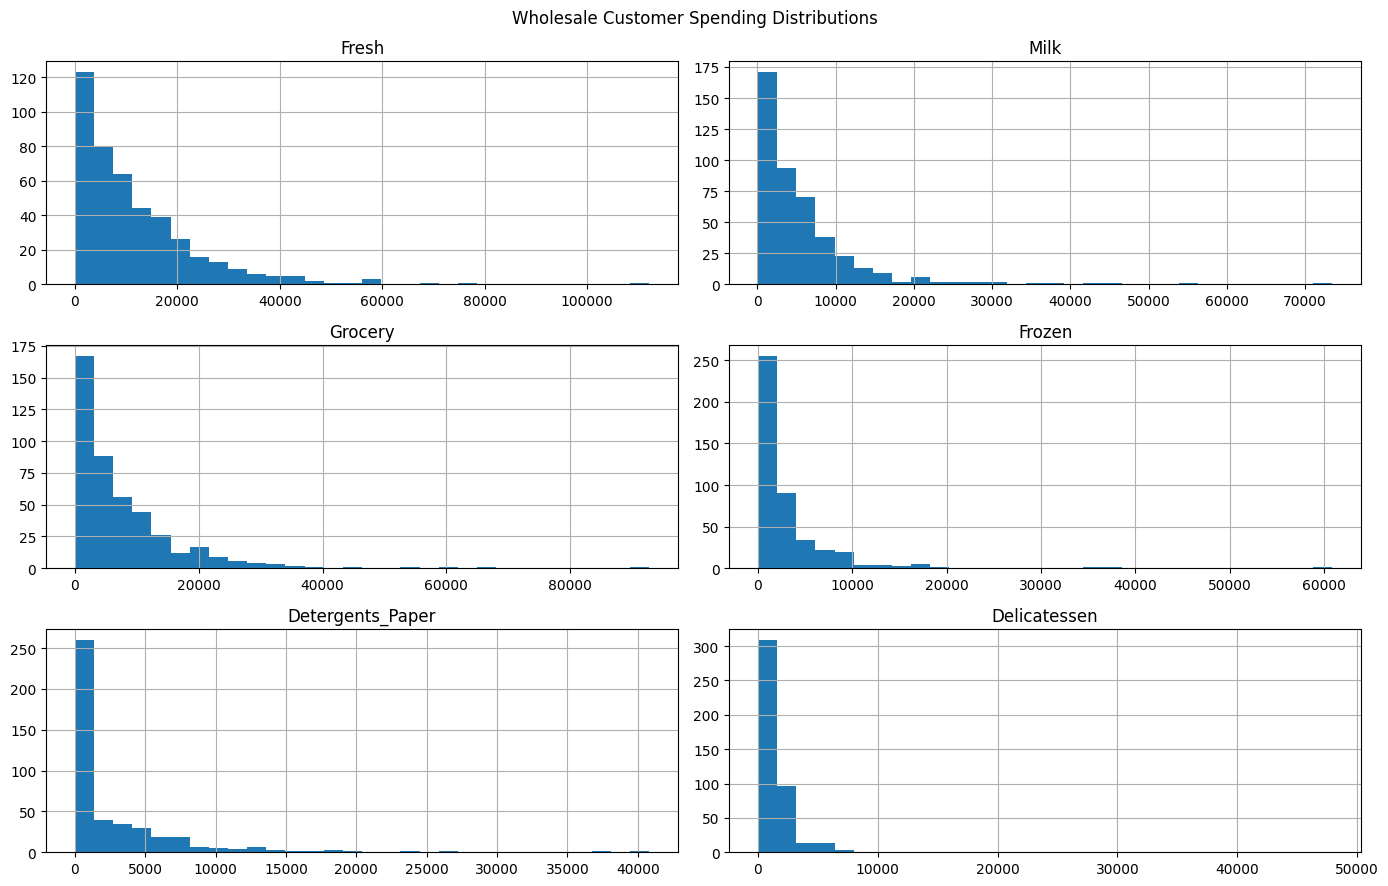

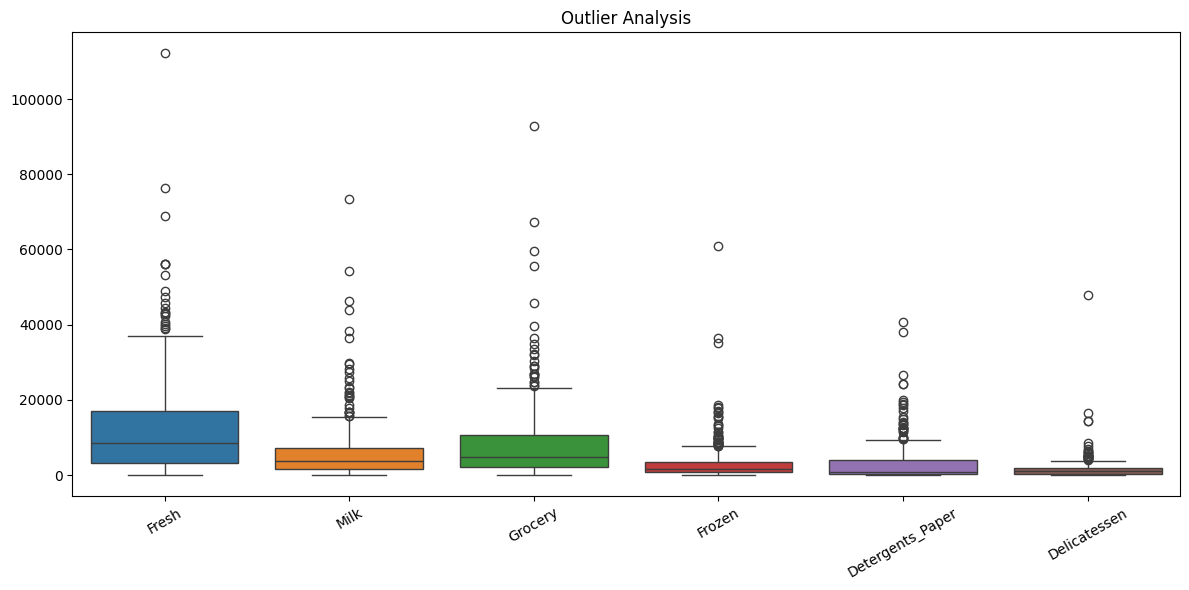

In [14]:
#  Defineing clustering variables
features = [
    "Fresh", "Milk", "Grocery",
    "Frozen", "Detergents_Paper",
    "Delicatessen"
]

X = df[features]

#  Descriptive statistics
print("\nDESCRIPTIVE STATISTICS")
print(X.describe().T)

# Checking for the Skewness of the data
print("\nSKEWNESS")
print(X.skew())

#  Histograms 
X.hist(figsize=(14, 9), bins=30)
plt.suptitle("Wholesale Customer Spending Distributions")
plt.tight_layout()
plt.show()

#  Boxplots
plt.figure(figsize=(12, 6))
sns.boxplot(data=X)
plt.xticks(rotation=30)
plt.title("Outlier Analysis")
plt.tight_layout()
plt.show()

from the statistical observation above
   Fresh products have the highest average annual expenditure (12,000.30 m.u.).
   Grocery products have the second-highest average expenditure (7,951.28 m.u.).
   Delicatessen products have the lowest average expenditure (1,524.87 m.u.).
   The mean is higher than the median for every spending category, suggesting positively skewed distributions.
 The large standard deviations indicate considerable variation in customer purchasing behaviour.
From the Histograms above
  The generated histogram analysis shows that all six spending variables are positively skewed. Most customers spend relatively small amounts, while a smaller number of customers account for exceptionally high expenditure.
 This suggests that the wholesale distributor serves customers with substantially different purchasing capacities.
Interpretation: The dataset does not exhibit normally distributed spending patterns. Applying clustering directly to the raw expenditure values could allow a few high-spending customers to dominate the distance calculations.
 


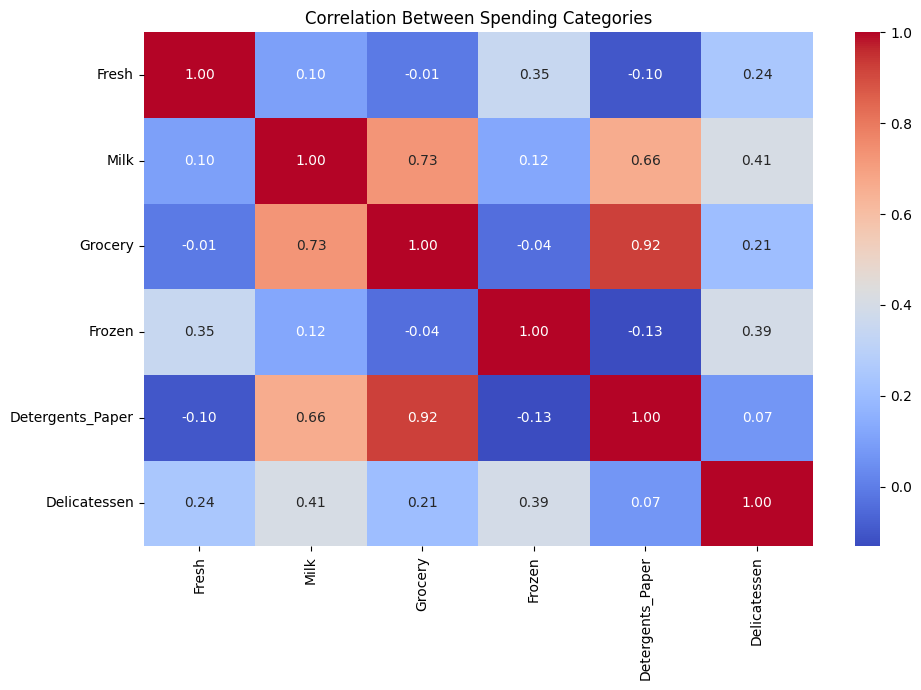

In [19]:
# Correlation analysis
plt.figure(figsize=(10, 7))
sns.heatmap(
    X.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Between Spending Categories")
plt.tight_layout()
plt.show()



Correlation analysis
 Correlation analysis was performed to investigate relationships between product categories.
    Product pair	                 Correlation	             Interpretation
    Grocery – Detergents_Paper	         0.92	                 Very strong positive
    Milk – Grocery	                     0.73	                 Strong positive
    Milk – Detergents_Paper	             0.66	                 Moderate-to-strong positive
    Fresh – Frozen	                     0.35	                 Moderate positive
    Milk – Delicatessen	                 0.41	                 Moderate positive
    Fresh – Grocery	                     -0.01	                 Almost no linear relationship

Key finding: Grocery and Detergents_Paper have a very strong positive correlation of 0.92. This indicates that customers who spend more on groceries also tend to spend more on detergents and paper products.

This relationship may help identify retail-oriented customers who purchase complementary product categories.

In [18]:
#  IQR outlier detection
print("\nIQR OUTLIER ANALYSIS")

for col in features:
    Q1 = X[col].quantile(0.25)
    Q3 = X[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = X[
        (X[col] < lower) | (X[col] > upper)
    ]

    print(col, ":", len(outliers))


IQR OUTLIER ANALYSIS
Fresh : 20
Milk : 28
Grocery : 24
Frozen : 43
Detergents_Paper : 30
Delicatessen : 27


From the above IRQ outlier analysis observation
- Frozen products have the highest number of potential outliers (43).
- Fresh products have 20 potential outliers.
- Delicatessen has an exceptionally high maximum expenditure of 47,943 m.u.
- The outliers may represent genuine wholesale customers with high purchasing volumes rather than incorrect observations.
Decision: The identified outliers should not automatically be deleted. High-spending customers are important to the segmentation exercise because they may represent valuable wholesale accounts. A logarithmic transformation is preferable to indiscriminate outlier removal

In [17]:

# Log transformation
X_log = np.log1p(X)

#  Standardisation
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

print("\nPREPARED DATA SHAPE:", X_scaled.shape)

# Hopkins statistic function
def hopkins_statistic(data, sample_size=44, seed=42):

    data = np.asarray(data)
    n, d = data.shape

    rng = np.random.default_rng(seed)

    indices = rng.choice(
        n, sample_size, replace=False
    )

    real_sample = data[indices]

    # Distances between actual observations
    nn = NearestNeighbors(n_neighbors=2)
    nn.fit(data)

    w = nn.kneighbors(
        real_sample
    )[0][:, 1]

    # Generate uniformly random observations
    random_data = rng.uniform(
        data.min(axis=0),
        data.max(axis=0),
        size=(sample_size, d)
    )

    # Distances from random observations
    # to nearest actual observations
    u = NearestNeighbors(n_neighbors=1)
    u.fit(data)

    distances = u.kneighbors(
        random_data
    )[0][:, 0]

    H = distances.sum() / (
        distances.sum() + w.sum()
    )

    return H

# Repeat Hopkins test 20 times
results = []

for seed in range(20):
    H = hopkins_statistic(
        X_scaled,
        sample_size=44,
        seed=seed
    )

    results.append(H)

print("\nHOPKINS RESULTS")
print("Individual values:", results)
print("Mean:", np.mean(results))
print("Standard deviation:", np.std(results))

#  Interpret results
average_H = np.mean(results)

if average_H > 0.75:
    print("Strong clustering tendency.")
elif average_H > 0.5:
    print("Evidence of clustering tendency.")
else:
    print("Weak clustering tendency.")

#  Save prepared dataset
prepared = pd.DataFrame(
    X_scaled,
    columns=features
)

prepared["Channel"] = df["Channel"]
prepared["Region"] = df["Region"]

prepared.to_csv(
    "wholesale_customers_prepared.csv",
    index=False
)

print("\nPrepared dataset saved successfully.")


PREPARED DATA SHAPE: (440, 6)

HOPKINS RESULTS
Individual values: [np.float64(0.8122277689750939), np.float64(0.7930587955793023), np.float64(0.8161331353093753), np.float64(0.788140319392558), np.float64(0.7985194448698659), np.float64(0.7945799467251093), np.float64(0.772900888482843), np.float64(0.7685004818748942), np.float64(0.7963242205081503), np.float64(0.8094288104996173), np.float64(0.794629723159614), np.float64(0.8098126034857657), np.float64(0.796424467205569), np.float64(0.7957653136026009), np.float64(0.8233204393249095), np.float64(0.7744027951611091), np.float64(0.7959111726603354), np.float64(0.78116906463819), np.float64(0.8198987495525887), np.float64(0.7946769081239471)]
Mean: 0.796791252456572
Standard deviation: 0.014838790167921636
Strong clustering tendency.

Prepared dataset saved successfully.


Investigating the need for clustering through Cluster tendency
 Cluster tendency refers to whether a dataset contains meaningful groups or natural structures that can be identified through clustering algorithms.
Before applying K-Means, hierarchical clustering or DBSCAN, it is important to establish whether the observations demonstrate a tendency to form clusters.

The prepared dataset produced an average Hopkins statistic of approximately 0.797.

This value is substantially greater than 0.5 and exceeds the commonly used 0.75 heuristic threshold. The results indicate that the wholesale customer observations are not randomly distributed in the six-dimensional spending space. There is evidence of underlying structure that may be discovered through clustering.

The raw dataset produced a higher Hopkins statistic of 0.932. However, this result may partly reflect the substantial skewness and extreme expenditure values. Therefore, the prepared-data result of 0.797 provides a more appropriate basis for proceeding with clustering.
Conclusion: Clustering is justified
The analysis provides sufficient evidence to proceed with customer segmentation using unsupervised machine learning techniques.

Overall findings and conclusion
  The exploratory analysis established that the wholesale customer dataset contains 440 observations and six principal expenditure variables. The dataset is complete, with no missing values or duplicate records.

  The descriptive analysis revealed substantial differences in spending behaviour. Fresh products account for the highest average expenditure, while delicatessen products account for the lowest. All six expenditure variables demonstrate positive skewness, indicating that a relatively small number of customers spend considerably more than the majority.

  The correlation analysis identified a particularly strong relationship between Grocery and Detergents_Paper (0.92), suggesting that certain customers purchase these categories together.

  Potential outliers were identified using the IQR method. Rather than deleting them, they were retained because high expenditure may represent genuine wholesale purchasing behaviour.

  Logarithmic transformation and standardisation were recommended to improve the suitability of the dataset for distance-based clustering.

Finally, the Hopkins statistic produced an average value of approximately 0.797 on the prepared data. This provides strong evidence of clustering tendency.

   Finally The wholesale customer dataset is suitable for further unsupervised machine learning analysis. The next stage should compare K-Means, hierarchical clustering and potentially DBSCAN, using appropriate cluster validation measures such as the Silhouette Score, Davies–Bouldin Index and Calinski–Harabasz Index. The resulting customer segments can then be translated into differentiated marketing, pricing, inventory and customer-retention strategies

Question 2

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Load dataset
df = pd.read_csv("wholesale-customers.csv")

# Select expenditure variables
features = [
    "Fresh",
    "Milk",
    "Grocery",
    "Frozen",
    "Detergents_Paper",
    "Delicatessen"
]

X = df[features]

# Log transformation
X_log = np.log1p(X)

# Standardisation
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

print("Prepared dataset:", X_scaled.shape)


Prepared dataset: (440, 6)


K-Means clustering

   Clusters  Silhouette  Davies_Bouldin  Calinski_Harabasz
0         2    0.290328        1.351502         189.049797
1         3    0.258278        1.348236         152.837245
2         4    0.188495        1.540772         131.319856
3         5    0.191585        1.484279         118.000499
4         6    0.195319        1.413524         108.299957
5         7    0.195780        1.391898         103.208189
6         8    0.191491        1.385463          97.385586


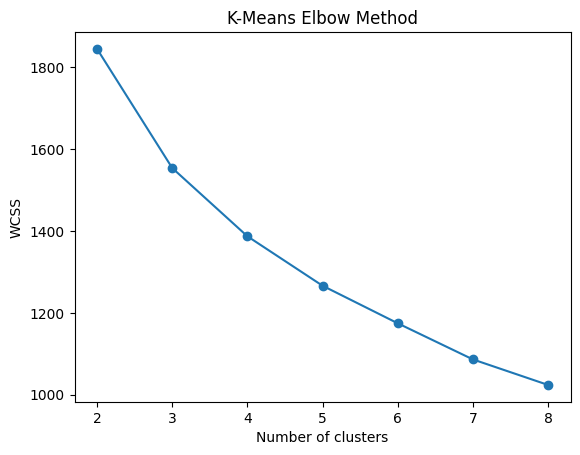

In [21]:
#K-Means clustering
# Test different cluster numbers
k_values = range(2, 9)

kmeans_results = []

for k in k_values:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(X_scaled)

    kmeans_results.append({
        "Clusters": k,
        "Silhouette": silhouette_score(
            X_scaled, labels
        ),
        "Davies_Bouldin": davies_bouldin_score(
            X_scaled, labels
        ),
        "Calinski_Harabasz": calinski_harabasz_score(
            X_scaled, labels
        )
    })

kmeans_table = pd.DataFrame(kmeans_results)

print(kmeans_table)

# Elbow method
wcss = []

for k in k_values:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    model.fit(X_scaled)
    wcss.append(model.inertia_)

plt.plot(list(k_values), wcss, marker="o")
plt.xlabel("Number of clusters")
plt.ylabel("WCSS")
plt.title("K-Means Elbow Method")
plt.show()


Hierarchical clustering

   Clusters  Silhouette  Davies_Bouldin  Calinski_Harabasz
0         2    0.258495        1.600363         134.624461
1         3    0.254657        1.538995         116.799278
2         4    0.202080        1.521091         108.606730
3         5    0.202547        1.386198         100.014606
4         6    0.170707        1.489516          94.856575
5         7    0.163338        1.498277          91.300533
6         8    0.148217        1.586505          86.612453


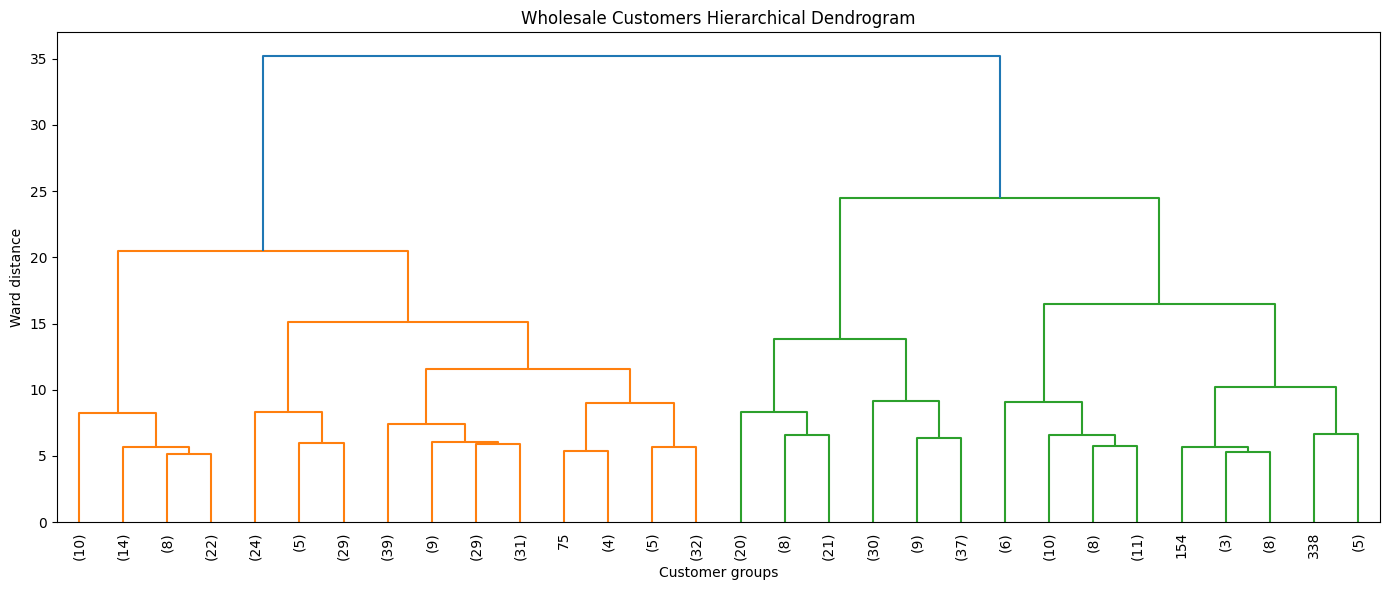

In [22]:

hierarchical_results = []

for k in range(2, 9):

    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )

    labels = model.fit_predict(X_scaled)

    hierarchical_results.append({
        "Clusters": k,
        "Silhouette": silhouette_score(
            X_scaled, labels
        ),
        "Davies_Bouldin": davies_bouldin_score(
            X_scaled, labels
        ),
        "Calinski_Harabasz": calinski_harabasz_score(
            X_scaled, labels
        )
    })

hierarchical_table = pd.DataFrame(
    hierarchical_results
)

print(hierarchical_table)

# Dendrogram
from scipy.cluster.hierarchy import (
    linkage,
    dendrogram
)

Z = linkage(X_scaled, method="ward")

plt.figure(figsize=(14, 6))

dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=90
)

plt.title("Wholesale Customers Hierarchical Dendrogram")
plt.xlabel("Customer groups")
plt.ylabel("Ward distance")
plt.tight_layout()
plt.show()


DBSCAN clustering
 For DBSCAN, different epsilon and minimum-samples values should be tested.

In [23]:

dbscan_results = []

for eps in np.arange(0.35, 2.05, 0.05):

    for min_samples in [4, 5, 8, 10]:

        model = DBSCAN(
            eps=eps,
            min_samples=min_samples
        )

        labels = model.fit_predict(X_scaled)

        # Exclude noise observations for
        # cluster validation metrics
        mask = labels != -1

        n_clusters = len(
            set(labels[mask])
        )

        noise_percentage = (
            1 - mask.mean()
        ) * 100

        if n_clusters >= 2 and mask.sum() > n_clusters:

            dbscan_results.append({
                "Epsilon": round(eps, 2),
                "Min_samples": min_samples,
                "Clusters": n_clusters,
                "Noise_percentage": round(
                    noise_percentage, 2
                ),
                "Silhouette": silhouette_score(
                    X_scaled[mask],
                    labels[mask]
                ),
                "Davies_Bouldin": davies_bouldin_score(
                    X_scaled[mask],
                    labels[mask]
                ),
                "Calinski_Harabasz": calinski_harabasz_score(
                    X_scaled[mask],
                    labels[mask]
                )
            })

dbscan_table = pd.DataFrame(dbscan_results)

if not dbscan_table.empty:
    print(
        dbscan_table.sort_values(
            "Silhouette",
            ascending=False
        ).head(15)
    )
else:
    print("No valid DBSCAN configuration found.")


    Epsilon  Min_samples  Clusters  Noise_percentage  Silhouette  \
7      0.65            8         3             91.59    0.580784   
10     0.70            8         3             90.23    0.553311   
18     0.80           10         2             75.91    0.537162   
17     0.80            8         2             66.59    0.507228   
22     0.85           10         2             65.23    0.503309   
2      0.55            5         5             93.18    0.476857   
25     0.90           10         2             56.36    0.461317   
14     0.75           10         3             87.50    0.449939   
21     0.85            8         2             56.59    0.445919   
0      0.50            4         6             94.32    0.438587   
1      0.55            4         6             88.64    0.375625   
13     0.75            8         4             77.95    0.371291   
9      0.70            5         4             77.95    0.364047   
4      0.60            5         7             8

Comparing the results


BEST K-MEANS MODEL
Clusters               2.000000
Silhouette             0.290328
Davies_Bouldin         1.351502
Calinski_Harabasz    189.049797
Name: 0, dtype: float64

BEST HIERARCHICAL MODEL
Clusters               2.000000
Silhouette             0.258495
Davies_Bouldin         1.600363
Calinski_Harabasz    134.624461
Name: 0, dtype: float64

BEST DBSCAN MODEL
Epsilon               0.900000
Min_samples           5.000000
Clusters              3.000000
Noise_percentage     36.360000
Silhouette            0.274144
Davies_Bouldin        0.810152
Calinski_Harabasz    26.354880
Name: 24, dtype: float64


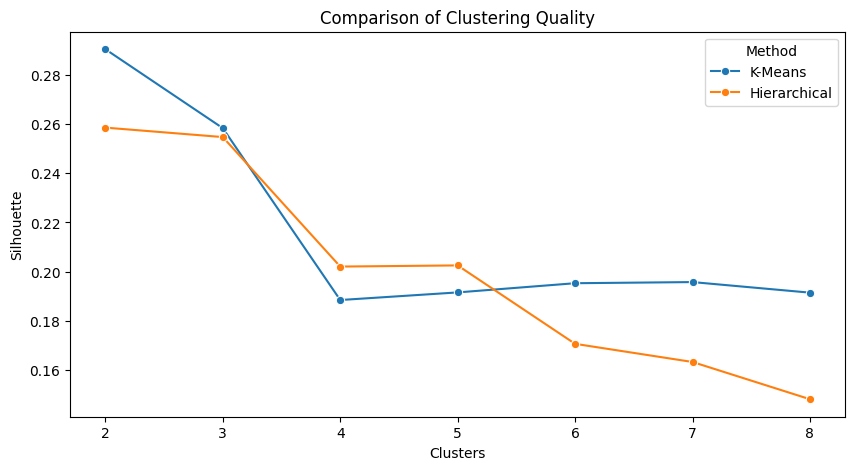

In [24]:

# Select best K-Means and hierarchical configurations
best_kmeans = kmeans_table.loc[
    kmeans_table["Silhouette"].idxmax()
]

best_hierarchical = hierarchical_table.loc[
    hierarchical_table["Silhouette"].idxmax()
]

print("\nBEST K-MEANS MODEL")
print(best_kmeans)

print("\nBEST HIERARCHICAL MODEL")
print(best_hierarchical)

if not dbscan_table.empty:

    # Consider DBSCAN models with less than 50% noise
    valid_dbscan = dbscan_table[
        dbscan_table["Noise_percentage"] < 50
    ]

    if not valid_dbscan.empty:

        best_dbscan = valid_dbscan.loc[
            valid_dbscan["Silhouette"].idxmax()
        ]

        print("\nBEST DBSCAN MODEL")
        print(best_dbscan)

# Compare cluster quality visually
comparison = pd.concat([
    kmeans_table.assign(Method="K-Means"),
    hierarchical_table.assign(
        Method="Hierarchical"
    )
])

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=comparison,
    x="Clusters",
    y="Silhouette",
    hue="Method",
    marker="o"
)

plt.title("Comparison of Clustering Quality")
plt.show()


Customer segment profiling
  After selecting the best-performing model, customer segments should be described using their original expenditure values.
  e.g the following code profiles a four-cluster K-Means solution.


CUSTOMER COUNTS
Customer_Segment
0     61
1    129
2    132
3    118
Name: count, dtype: int64

CUSTOMER SPENDING PROFILES
                     Fresh      Milk   Grocery   Frozen  Detergents_Paper  \
Customer_Segment                                                            
0                  2809.05   7061.84  12349.33   565.59           5342.62   
1                 19374.38   4068.11   4444.94  6184.33            723.33   
2                  9632.66   1569.58   2071.87  2175.23            345.01   
3                 11338.75  11759.44  16087.87  1968.13           6805.99   

                  Delicatessen  
Customer_Segment                
0                       635.84  
1                      2322.71  
2                       584.81  
3                      2163.83  


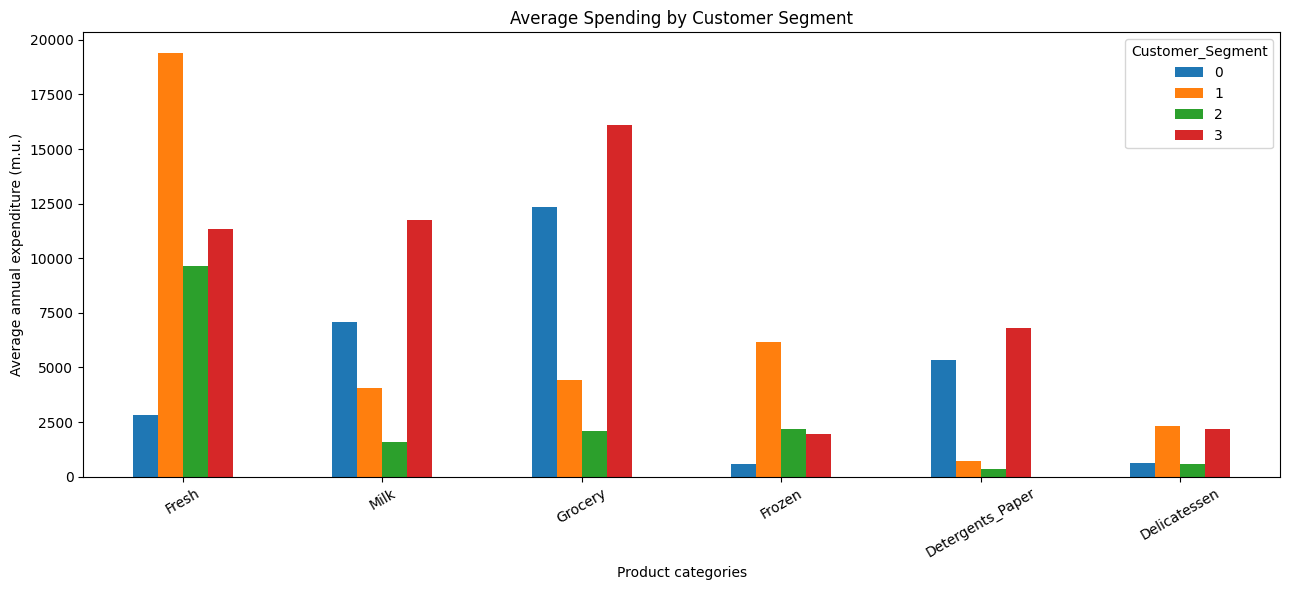


CHANNEL DISTRIBUTION
Channel              1     2
Customer_Segment            
0                 0.34  0.66
1                 0.95  0.05
2                 0.99  0.01
3                 0.20  0.80

REGION DISTRIBUTION
Region               1     2     3
Customer_Segment                  
0                 0.13  0.10  0.77
1                 0.16  0.13  0.71
2                 0.20  0.08  0.71
3                 0.18  0.11  0.71


In [25]:

# Fit illustrative K-Means model
final_model = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=20
)

df["Customer_Segment"] = final_model.fit_predict(
    X_scaled
)

# Cluster sizes
print("\nCUSTOMER COUNTS")
print(
    df["Customer_Segment"].value_counts()
    .sort_index()
)

# Average expenditure by segment
profile = df.groupby(
    "Customer_Segment"
)[features].mean().round(2)

print("\nCUSTOMER SPENDING PROFILES")
print(profile)

# Visualise customer segments
profile.T.plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("Average Spending by Customer Segment")
plt.ylabel("Average annual expenditure (m.u.)")
plt.xlabel("Product categories")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Include channel and region information
print("\nCHANNEL DISTRIBUTION")
print(
    pd.crosstab(
        df["Customer_Segment"],
        df["Channel"],
        normalize="index"
    ).round(2)
)

print("\nREGION DISTRIBUTION")
print(
    pd.crosstab(
        df["Customer_Segment"],
        df["Region"],
        normalize="index"
    ).round(2)
)

# Save segmented dataset
df.to_csv(
    "wholesale_customers_segmented.csv",
    index=False
)


The three clustering approaches provide complementary methods for understanding wholesale customer purchasing behaviour.

K-Means is attractive because it produces clear and easily interpretable customer segments. Hierarchical clustering provides a visual understanding of similarities and relationships between customers. DBSCAN is valuable for identifying dense customer groups and unusual purchasing patterns.

However, the most appropriate model should be selected based on empirical evidence from the Silhouette coefficient, Davies–Bouldin Index, Calinski–Harabasz Index, cluster sizes and interpretability

     From the findings comparing K-Meas, Davies-Bouldin Index and Calinski-HarabaszIndex
Silhouette Score
K-Means achieves the highest Silhouette Score of 0.2903. This suggests that its two customer groups have better overall separation and cohesion than the hierarchical solution. DBSCAN performs slightly below K-Means, with a score of 0.2741. However, all three scores are relatively modest, suggesting that the customer groups overlap to some extent.

Davies–Bouldin Index
The Davies–Bouldin Index evaluates the similarity between clusters. A lower value indicates better cluster separation and compactness.
From the above results, DBSCAN achieves the lowest Davies–Bouldin Index of 0.8102, suggesting that its identified clusters are more compact and distinct under this measure. However, this result must be interpreted carefully because DBSCAN classified 36.36% of customers as noise. Its score was calculated using only the non-noise observations, unlike the K-Means and hierarchical scores, which included all customers. Therefore, the three Davies–Bouldin values are not directly comparable.

Calinski–Harabasz Index
Higher values generally indicate better-defined clusters. K-Means achieves the highest value of 189.05. This suggests that its two clusters have a stronger separation relative to their internal variation. DBSCAN has a considerably lower score. Again, its score is calculated on a smaller subset of customers because noise observations were excluded.
Overall, K-Means provides the most practical balance between clustering quality, customer coverage and business interpretability for this study.


compare the cluster sizes and expenditure profiles of the two K-Means clusters.

In [26]:
# Cluster sizes
print(df["Customer_Segment"].value_counts())

# Average expenditure per cluster
print(
    df.groupby("Customer_Segment")[
        ["Fresh", "Milk", "Grocery",
         "Frozen", "Detergents_Paper",
         "Delicatessen"]
    ].mean().round(2)
)

# Median expenditure per cluster
print(
    df.groupby("Customer_Segment")[
        ["Fresh", "Milk", "Grocery",
         "Frozen", "Detergents_Paper",
         "Delicatessen"]
    ].median().round(2)
)

Customer_Segment
2    132
1    129
3    118
0     61
Name: count, dtype: int64
                     Fresh      Milk   Grocery   Frozen  Detergents_Paper  \
Customer_Segment                                                            
0                  2809.05   7061.84  12349.33   565.59           5342.62   
1                 19374.38   4068.11   4444.94  6184.33            723.33   
2                  9632.66   1569.58   2071.87  2175.23            345.01   
3                 11338.75  11759.44  16087.87  1968.13           6805.99   

                  Delicatessen  
Customer_Segment                
0                       635.84  
1                      2322.71  
2                       584.81  
3                      2163.83  
                    Fresh    Milk  Grocery  Frozen  Detergents_Paper  \
Customer_Segment                                                       
0                  1073.0  6964.0  10518.0   340.0            4508.0   
1                 17023.0  3086.0   3445.0  

Final recommendation: We should select K-Means with two clusters as the preferred model based on my current results, however,the relatively low Silhouette Score means there is room for improvement and further validation.

Question 3

Generate the cluster profiles

In [27]:

import pandas as pd
import numpy as np

# Spending categories
features = [
    "Fresh",
    "Milk",
    "Grocery",
    "Frozen",
    "Detergents_Paper",
    "Delicatessen"
]

# Fit the selected K-Means model
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

# Number of customers in each cluster
print("\nCUSTOMER DISTRIBUTION")
print(df["Cluster"].value_counts().sort_index())

# Calculate average spending
cluster_means = df.groupby("Cluster")[features].mean()

print("\nAVERAGE SPENDING BY CLUSTER")
print(cluster_means.round(2))

# Calculate median spending
cluster_medians = df.groupby("Cluster")[features].median()

print("\nMEDIAN SPENDING BY CLUSTER")
print(cluster_medians.round(2))

# Calculate total average expenditure
cluster_means["Total_Spending"] = (
    cluster_means[features].sum(axis=1)
)

print("\nTOTAL AVERAGE SPENDING")
print(cluster_means["Total_Spending"])

# Calculate percentage contribution of each category
percentage = (
    cluster_means[features]
    .div(cluster_means[features].sum(axis=1), axis=0)
    * 100
)

print("\nSPENDING COMPOSITION (%)")
print(percentage.round(2))

# Export results
cluster_means.to_csv("cluster_average_profiles.csv")
cluster_medians.to_csv("cluster_median_profiles.csv")
percentage.to_csv("cluster_spending_composition.csv")



CUSTOMER DISTRIBUTION
Cluster
0    252
1    188
Name: count, dtype: int64

AVERAGE SPENDING BY CLUSTER
            Fresh      Milk   Grocery   Frozen  Detergents_Paper  Delicatessen
Cluster                                                                       
0        13973.13   2401.75   2918.71  3705.67            491.94       1038.04
1         9355.87  10346.36  14697.06  2222.45           6084.51       2177.43

MEDIAN SPENDING BY CLUSTER
           Fresh    Milk  Grocery  Frozen  Detergents_Paper  Delicatessen
Cluster                                                                  
0        10347.5  1871.0   2406.0  2225.0             327.5         749.5
1         5406.5  7690.5  11527.0  1061.5            4495.0        1388.5

TOTAL AVERAGE SPENDING
Cluster
0    24529.242063
1    44883.675532
Name: Total_Spending, dtype: float64

SPENDING COMPOSITION (%)
         Fresh   Milk  Grocery  Frozen  Detergents_Paper  Delicatessen
Cluster                                               

Cluster	    Suggested descriptive name	           Spending characteristics
Cluster 0	High-Volume Wholesale Customers	          Relatively high expenditure across several product categories
Cluster 1	Low-Volume Wholesale Customers	          Relatively low expenditure across most product categories

Cluster 0 contains the majority of customers, accounting for approximately 57.27% of the customer base, while Cluster 1 accounts for 42.73%.

Cluster 0
252 customers
  Fresh-Product-Oriented Customers
These customers demonstrate a strong preference for fresh products, with comparatively lower expenditure on milk, groceries and detergents.
Cluster 1
188 Customers
   Grocery, Milk and Household Products-Oriented Customers. These custores demonstrate a strong preference for grocery, milkand house hold products.

Recommended strategy: Offer bulk-purchasing discounts, loyalty rewards, product bundles and priority delivery services to retain these customers and increase their purchasing volumes.


                              THE END